# Deforestation detection

Forest cover loss in the Rondônia deforestation arc, Brazil, from Sentinel-2 L2A imagery on Microsoft Planetary Computer. Two dry-season windows are compared, June to September 2018 and June to September 2023, and the drop in vegetation between them is turned into a ranked list of areas to inspect.

The logic lives in `utils.py`; this notebook runs the steps in order and shows the results. Everything it produces is written to `outputs/`, which `02_validation.ipynb` then reads.

In [1]:
%load_ext autoreload
%autoreload 2

import json
from datetime import date
from pathlib import Path
import xarray as xr
import folium
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import planetary_computer as pc
import pystac_client
from folium.plugins import GroupedLayerControl
from shapely.geometry import Point

from utils import (
    search_wide_area,
    choose_aoi,
    find_candidates,
    pick_scenes,
    load_scene,
    mask_and_scale,
    valid_observation_count,
    ndvi,
    ndmi,
    evi,
    bsi,
    false_color,
    period_median,
    vectorize_loss,
    water_like_polygons,
    build_alerts,
    summarise_alerts,
    raster_to_overlay,
)

## 1. Settings

All the choices of the analysis in one place. Both periods cover the same dry-season months (June to September), so seasonal effects don't get mixed up with the actual change.

In [2]:
REFERENCE_POINT = Point(-63.90, -8.76)   # Porto Velho, the state capital; used only to find
                                          # the tiles, the AOI ends up ~95 km south-east
SEARCH_RADIUS_DEG = 0.5                  # wide area used only to choose the AOI
AOI_HALF_SIZE_DEG = 0.05                 # AOI of roughly 10 x 10 km

BASELINE_WINDOW = "2018-06-01/2018-09-30"
RECENT_WINDOW = "2023-06-01/2023-09-30"

# SCL classes treated as unusable: no data, saturated, shadow, clouds, cirrus, snow
BAD_SCL_CLASSES = [0, 1, 3, 8, 9, 10, 11]

BANDS = ["B02", "B03", "B04", "B08", "B8A", "B11", "B12", "SCL"]
# B08 (broad NIR, 10 m) is used for the spectral indices.
# B8A (narrow NIR, 20 m) is needed only by the foundation model section.

# Alert rule
CHANGE_THRESHOLD = -0.25            # NDVI drop that flags a pixel
MIN_AREA_M2 = 5000                  # half a hectare: smaller patches are treated as noise
BSI_CONFIRMATION_THRESHOLD = 0.05   # mean bare-soil increase needed to confirm a polygon
WATER_NDVI_THRESHOLD = -0.1         # NDVI below this in both periods = likely water

# Where results go
OUTPUT_DIR = Path("outputs")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

## 2. Connect to the catalog

`sign_inplace` adds a temporary access token to every asset URL, since the files sit on private Azure storage. Tokens expire after about a day: if loading fails later with odd rasterio errors, rerun the searches.

In [3]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=pc.sign_inplace,
)

## 3. Choose the AOI

The AOI must sit entirely inside a single Sentinel-2 swath, otherwise part of it is empty in some scenes. The AOI is placed well inside the footprint of the largest scene found around the reference point.

The reference point, Porto Velho, is used only to find which tiles cover the region: the AOI is then centred inside the largest footprint, and in this run it lies about 95 km south-east of the point, still within the Rondônia deforestation arc.

In [4]:
wide_area = REFERENCE_POINT.buffer(SEARCH_RADIUS_DEG)
nearby_scenes = search_wide_area(catalog, wide_area, RECENT_WINDOW)
print(len(nearby_scenes), "scenes found around the reference point")

bbox, aoi_geojson = choose_aoi(nearby_scenes, half_size=AOI_HALF_SIZE_DEG)
print("bbox:", bbox)

243 scenes found around the reference point
bbox: [-63.461313123204675, -9.592136744908483, -63.36131312320468, -9.492136744908482]


## 4. Select the scenes

Two filters: a cheap one on tile-level cloud cover (metadata only), then a precise one on the share of usable pixels inside the AOI, read from the SCL band. The five clearest scenes of each period are kept.

In [5]:
baseline_candidates = find_candidates(catalog, aoi_geojson, BASELINE_WINDOW)
recent_candidates = find_candidates(catalog, aoi_geojson, RECENT_WINDOW)
print("baseline candidates:", len(baseline_candidates))
print("recent candidates:", len(recent_candidates))

baseline candidates: 18
recent candidates: 30


In [6]:
baseline_scenes = pick_scenes(baseline_candidates, bbox, BAD_SCL_CLASSES)
recent_scenes = pick_scenes(recent_candidates, bbox, BAD_SCL_CLASSES)

for period, selected in [("baseline", baseline_scenes), ("recent", recent_scenes)]:
    print(f"{period} scenes:")
    for item in selected:
        print(" ", item.id, item.properties["datetime"][:10])

total_scenes = len(baseline_scenes) + len(recent_scenes)
assert total_scenes >= 6, "not enough clean scenes, try widening the date range"
print(f"{total_scenes} acquisitions in total")

baseline scenes:
  S2A_MSIL2A_20180819T142751_R053_T20LMQ_20201011T035719 2018-08-19
  S2A_MSIL2A_20180829T142751_R053_T20LMQ_20201103T112224 2018-08-29
  S2A_MSIL2A_20180720T142751_R053_T20LMQ_20201011T175511 2018-07-20
  S2A_MSIL2A_20180908T142751_R053_T20LMQ_20201011T100319 2018-09-08
  S2A_MSIL2A_20180710T142751_R053_T20LMQ_20201011T140724 2018-07-10
recent scenes:
  S2B_MSIL2A_20230629T142719_R053_T20LMQ_20241002T184523 2023-06-29
  S2A_MSIL2A_20230724T142721_R053_T20LMQ_20230724T233545 2023-07-24
  S2A_MSIL2A_20230922T142711_R053_T20LMQ_20241026T093629 2023-09-22
  S2B_MSIL2A_20230828T142719_R053_T20LMQ_20241019T002816 2023-08-28
  S2B_MSIL2A_20230808T142719_R053_T20LMQ_20241030T021940 2023-08-08
10 acquisitions in total


## 5. Load the pixels

Each scene is prepared on a common 10 m grid over the AOI. Loading is lazy: nothing is downloaded until the values are actually used.

In [7]:
all_scenes = [("baseline", item) for item in baseline_scenes] + \
             [("recent", item) for item in recent_scenes]

scenes = {}
for period, item in all_scenes:
    scenes[item.id] = {
        "period": period,
        "date": item.properties["datetime"],
        "data": load_scene(item, bbox, BANDS),
    }
    print(f"prepared {item.id} ({period}, {item.properties['datetime'][:10]})")

item_by_id = {item.id: item for item in baseline_scenes + recent_scenes}

prepared S2A_MSIL2A_20180819T142751_R053_T20LMQ_20201011T035719 (baseline, 2018-08-19)
prepared S2A_MSIL2A_20180829T142751_R053_T20LMQ_20201103T112224 (baseline, 2018-08-29)
prepared S2A_MSIL2A_20180720T142751_R053_T20LMQ_20201011T175511 (baseline, 2018-07-20)
prepared S2A_MSIL2A_20180908T142751_R053_T20LMQ_20201011T100319 (baseline, 2018-09-08)
prepared S2A_MSIL2A_20180710T142751_R053_T20LMQ_20201011T140724 (baseline, 2018-07-10)
prepared S2B_MSIL2A_20230629T142719_R053_T20LMQ_20241002T184523 (recent, 2023-06-29)
prepared S2A_MSIL2A_20230724T142721_R053_T20LMQ_20230724T233545 (recent, 2023-07-24)
prepared S2A_MSIL2A_20230922T142711_R053_T20LMQ_20241026T093629 (recent, 2023-09-22)
prepared S2B_MSIL2A_20230828T142719_R053_T20LMQ_20241019T002816 (recent, 2023-08-28)
prepared S2B_MSIL2A_20230808T142719_R053_T20LMQ_20241030T021940 (recent, 2023-08-08)


## 6. Mask and scale

Raw Sentinel-2 values are turned into surface reflectance, and pixels flagged by the SCL band as clouds, shadows, snow or missing data are set to NaN. Scenes processed with baseline 04.00 or later (from January 2022) carry a radiometric offset of 1000 that Planetary Computer does not remove: skipping this correction makes the 2023 scenes look systematically brighter than the 2018 ones and produces a false vegetation loss.

This is also where the pixels are actually downloaded. `.compute()` runs the lazy pipeline once and keeps the result in memory, so everything that follows works on real arrays instead of fetching the same bands again.

In [8]:
for scene_id, info in scenes.items():
    info["clean"] = mask_and_scale(info["data"], item_by_id[scene_id]).compute()
    baseline_used = item_by_id[scene_id].properties.get("s2:processing_baseline", "unknown")
    offset_applied = float(baseline_used.split(".")[0]) >= 4
    print(f"{scene_id[:25]}... | processing baseline {baseline_used} | offset corrected: {offset_applied}")

S2A_MSIL2A_20180819T14275... | processing baseline 02.12 | offset corrected: False
S2A_MSIL2A_20180829T14275... | processing baseline 02.12 | offset corrected: False
S2A_MSIL2A_20180720T14275... | processing baseline 02.12 | offset corrected: False
S2A_MSIL2A_20180908T14275... | processing baseline 02.12 | offset corrected: False
S2A_MSIL2A_20180710T14275... | processing baseline 02.12 | offset corrected: False
S2B_MSIL2A_20230629T14271... | processing baseline 05.10 | offset corrected: True
S2A_MSIL2A_20230724T14272... | processing baseline 05.09 | offset corrected: True
S2A_MSIL2A_20230922T14271... | processing baseline 05.10 | offset corrected: True
S2B_MSIL2A_20230828T14271... | processing baseline 05.10 | offset corrected: True
S2B_MSIL2A_20230808T14271... | processing baseline 05.10 | offset corrected: True


## 7. Check how much data survived masking

For each pixel, count in how many of the five scenes of a period it is still usable. The period composites are medians across scenes, so a pixel with only one or two clear observations would rest on very little evidence.

The scenes were already picked for being clear over the AOI, so this mostly confirms that choice. It is still worth a look before trusting the medians, to catch a scene with a bad patch sitting right inside the AOI.

In [9]:
for period_name in ["baseline", "recent"]:
    valid_count = valid_observation_count(period_name, scenes)
    mean_valid = float(valid_count.mean().values)
    pct_well_covered = float((valid_count >= 3).mean().values) * 100
    print(f"{period_name}: average of {mean_valid:.1f} clear observations per pixel out of 5, "
          f"{pct_well_covered:.1f}% of pixels have at least 3 clear observations")

baseline: average of 5.0 clear observations per pixel out of 5, 100.0% of pixels have at least 3 clear observations
recent: average of 5.0 clear observations per pixel out of 5, 100.0% of pixels have at least 3 clear observations


## 8. Compute the spectral indices

Four indices are computed for every scene, each looking at the land from a different angle:

- **NDVI**: vegetation vigour, the standard starting point.
- **EVI**: also vegetation vigour, but less prone to saturating over dense canopy.
- **NDMI**: canopy moisture and structure, sensitive to disturbance that NDVI can miss.
- **BSI**: bare soil, which is what clearing leaves behind.

A drop in NDVI together with a rise in BSI is stronger evidence of clearing than either signal alone, and this is the idea behind the alert rule further down.

In [10]:
for scene_id, info in scenes.items():
    info["ndvi"] = ndvi(info["clean"])
    info["ndmi"] = ndmi(info["clean"])
    info["evi"] = evi(info["clean"])
    info["bsi"] = bsi(info["clean"])

print("NDVI, NDMI, EVI and BSI computed for", len(scenes), "individual scenes")


NDVI, NDMI, EVI and BSI computed for 10 individual scenes


## 9. Sanity check on the index values

One row per scene, with the mean of each index over the AOI. Checking scene by scene, before anything is merged into period composites, makes a badly masked or odd acquisition stand out early.

Two things to look for. The NDVI ranges of the two periods should overlap: a systematic gap between 2018 and 2023 would point to a scaling problem rather than a real change, and this table is the first place where the offset correction above can be seen to work. And the indices should agree with each other: the driest scene should show low NDVI, low NDMI and high BSI on the same date.

In [11]:
summary_rows = []
for scene_id, info in scenes.items():
    summary_rows.append({
        "scene_id": scene_id,
        "date": info["date"][:10],
        "period": info["period"],
        "mean_ndvi": float(info["ndvi"].mean(skipna=True).values),
        "mean_ndmi": float(info["ndmi"].mean(skipna=True).values),
        "mean_evi": float(info["evi"].mean(skipna=True).values),
        "mean_bsi": float(info["bsi"].mean(skipna=True).values),
    })

summary_df = pd.DataFrame(summary_rows).sort_values("date").reset_index(drop=True)
summary_df


,scene_id,date,period,mean_ndvi,mean_ndmi,mean_evi,mean_bsi
0,S2A_MSIL2A_20180710T142751_R053_T20LMQ_2020101...,2018-07-10,baseline,0.587672,0.035249,0.360422,0.006895
1,S2A_MSIL2A_20180720T142751_R053_T20LMQ_2020101...,2018-07-20,baseline,0.533233,-0.021580,0.326221,0.055539
2,S2A_MSIL2A_20180819T142751_R053_T20LMQ_2020101...,2018-08-19,baseline,0.512915,-0.047242,0.331971,0.067894
3,S2A_MSIL2A_20180829T142751_R053_T20LMQ_2020110...,2018-08-29,baseline,0.537851,-0.016286,0.365634,0.038836
4,S2A_MSIL2A_20180908T142751_R053_T20LMQ_2020101...,2018-09-08,baseline,0.449355,-0.030979,0.362957,0.037565
5,S2B_MSIL2A_20230629T142719_R053_T20LMQ_2024100...,2023-06-29,recent,0.598813,0.060362,0.401679,-0.028464
6,S2A_MSIL2A_20230724T142721_R053_T20LMQ_2023072...,2023-07-24,recent,0.496428,-0.037811,0.311296,0.076704
7,S2B_MSIL2A_20230808T142719_R053_T20LMQ_2024103...,2023-08-08,recent,0.429804,-0.085736,0.289251,0.106538
8,S2B_MSIL2A_20230828T142719_R053_T20LMQ_2024101...,2023-08-28,recent,0.498611,-0.031541,0.346489,0.049733
9,S2A_MSIL2A_20230922T142711_R053_T20LMQ_2024102...,2023-09-22,recent,0.568109,0.015188,0.410962,0.011588


## 10. A visual check, one map per scene

A mean can hide a scene where most of the AOI was masked and the average rests on a sliver of pixels. A grid of NDVI maps, one per acquisition and all on the same colour scale, makes that kind of problem visible at a glance.

It also shows what stays the same across dates. A patch that looks identical in all ten panels, in both years, is a permanent feature such as water, not a change.

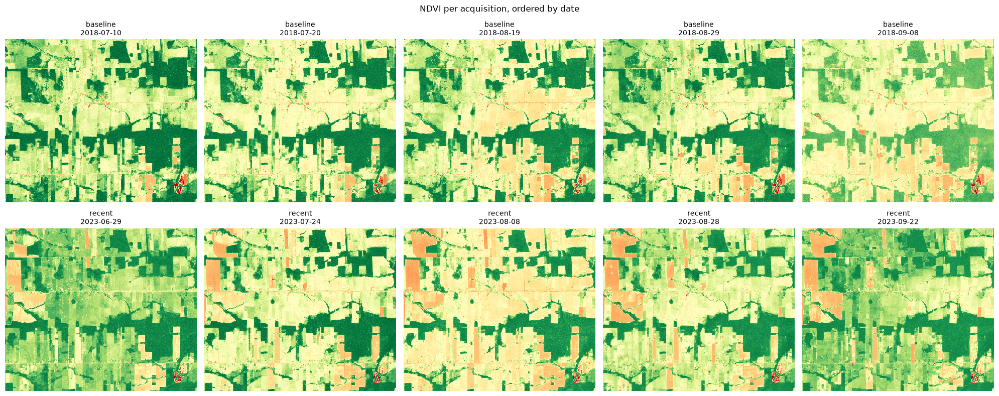

In [12]:
ordered_scenes = sorted(scenes.items(), key=lambda kv: kv[1]["date"])

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for ax, (scene_id, info) in zip(axes, ordered_scenes):
    info["ndvi"].plot(ax=ax, cmap="RdYlGn", vmin=-0.2, vmax=0.9, add_colorbar=False)
    ax.set_title(f"{info['period']}\n{info['date'][:10]}", fontsize=10)
    ax.axis("off")

plt.suptitle("NDVI per acquisition, ordered by date")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ndvi_per_acquisition_grid.png", dpi=150)
plt.show()

## 11. All four indices at a glance

The same per-scene means as in the table, plotted over time. The marker shape tells the index, the colour tells the period: blue for baseline, red for recent.

The points fall into two horizontal bands. NDVI and EVI sit higher because vegetation indices naturally range higher over green land, while NDMI and BSI stay close to zero and move either way with moisture and bare soil. The gap between the bands comes from the indices having different natural scales, and they share one axis only for convenience. What matters is that within each band the blue and red points overlap instead of forming two separate clusters.

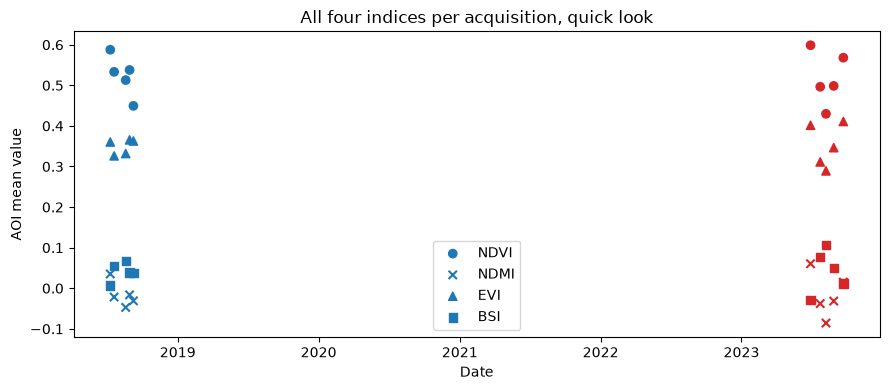

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
colors = summary_df["period"].map({"baseline": "tab:blue", "recent": "tab:red"})
dates = pd.to_datetime(summary_df["date"])

ax.scatter(dates, summary_df["mean_ndvi"], c=colors, marker="o", label="NDVI")
ax.scatter(dates, summary_df["mean_ndmi"], c=colors, marker="x", label="NDMI")
ax.scatter(dates, summary_df["mean_evi"], c=colors, marker="^", label="EVI")
ax.scatter(dates, summary_df["mean_bsi"], c=colors, marker="s", label="BSI")
ax.set_xlabel("Date")
ax.set_ylabel("AOI mean value")
ax.set_title("All four indices per acquisition, quick look")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "indices_quick_look.png", dpi=150)
plt.show()

## 12. False colour composite

Near infrared, red and green are shown as red, green and blue. Healthy vegetation reflects strongly in the near infrared, so it appears bright red, while water turns dark blue and bare soil or dry pasture looks cyan to grey. It is the quickest way to see whether the AOI is forest, farmland or a mix of the two.

Each panel is stretched on its own 2nd to 98th percentile, so the same reflectance can map to a different colour in the two dates. Only the spatial pattern within a panel can be compared directly, and the overall hue should not be read as a change in the landscape.

The two dates shown are the pair closest in the season, so that the comparison is not distorted by the dry season advancing.

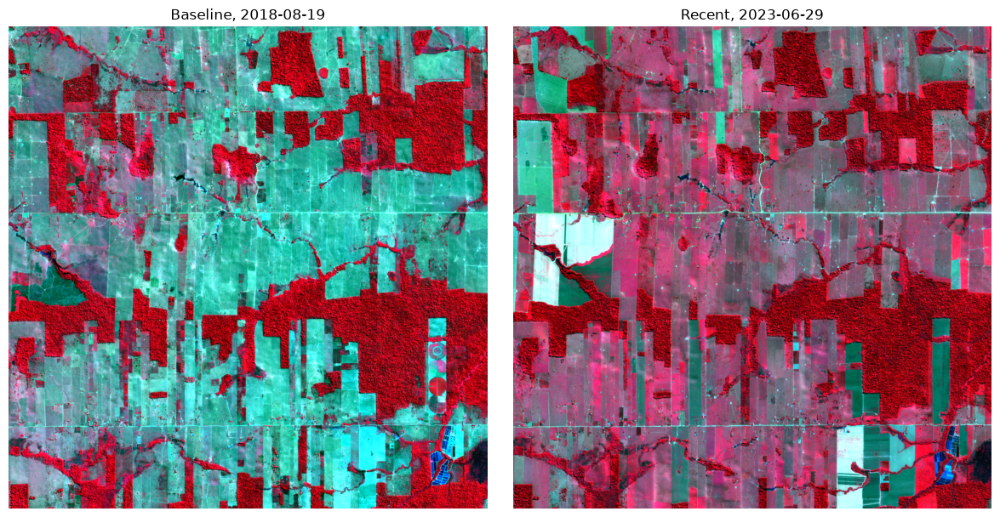

In [14]:
# the pair of dates closest in the season, so the comparison is not a June-vs-August one
day_of_year = lambda info: pd.Timestamp(info["date"]).dayofyear
baseline_example, recent_example = min(
    ((b, r) for b in scenes.values() if b["period"] == "baseline"
            for r in scenes.values() if r["period"] == "recent"),
    key=lambda pair: abs(day_of_year(pair[0]) - day_of_year(pair[1])),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(false_color(baseline_example["clean"]))
axes[0].set_title(f"Baseline, {baseline_example['date'][:10]}")
axes[0].axis("off")
axes[1].imshow(false_color(recent_example["clean"]))
axes[1].set_title(f"Recent, {recent_example['date'][:10]}")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "false_color_comparison.png", dpi=150)
plt.show()

## 13. NDVI time series

Mean NDVI over the AOI, one point per acquisition. Each period is drawn as its own line, so nothing connects 2018 to 2023 across the years in between, for which there is no data. The plot shows two separate dry-season windows and should not be read as a continuous trend.

Within each window, NDVI is expected to drift down as the dry season goes on and vegetation dries out. The two windows should sit at a comparable level, since any real loss affects only part of the AOI and barely moves its overall mean.

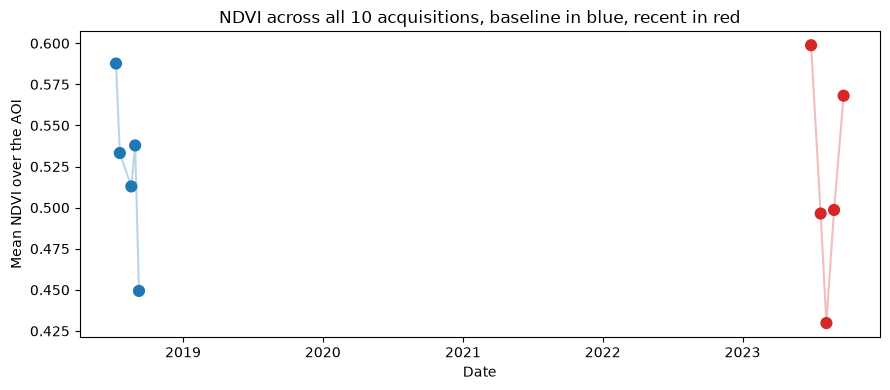

In [15]:
fig, ax = plt.subplots(figsize=(9, 4))

for period_name, color in [("baseline", "tab:blue"), ("recent", "tab:red")]:
    period_rows = summary_df[summary_df["period"] == period_name].sort_values("date")
    period_dates = pd.to_datetime(period_rows["date"])
    ax.plot(period_dates, period_rows["mean_ndvi"], alpha=0.3, color=color)

colors = summary_df["period"].map({"baseline": "tab:blue", "recent": "tab:red"})
dates = pd.to_datetime(summary_df["date"])
ax.scatter(dates, summary_df["mean_ndvi"], c=colors, s=60)

ax.set_xlabel("Date")
ax.set_ylabel("Mean NDVI over the AOI")
ax.set_title("NDVI across all 10 acquisitions, baseline in blue, recent in red")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ndvi_time_series.png", dpi=150)
plt.show()

## 14. Period composites and change map

Each period is collapsed into a single map per index by taking the per-pixel median across its five scenes. The median fills the gaps left by masked pixels and is not thrown off by a single odd acquisition. Recent minus baseline then gives the change, where negative NDVI values mean vegetation loss.

This is done for all four indices, since they are all used later, but the NDVI change is the one saved to disk, as a Cloud Optimized GeoTIFF with its coordinate reference system attached.

medians and change computed for ndvi, ndmi, evi, bsi
saved ndvi_change.tif, CRS: EPSG:32720 shape: (1108, 1100)


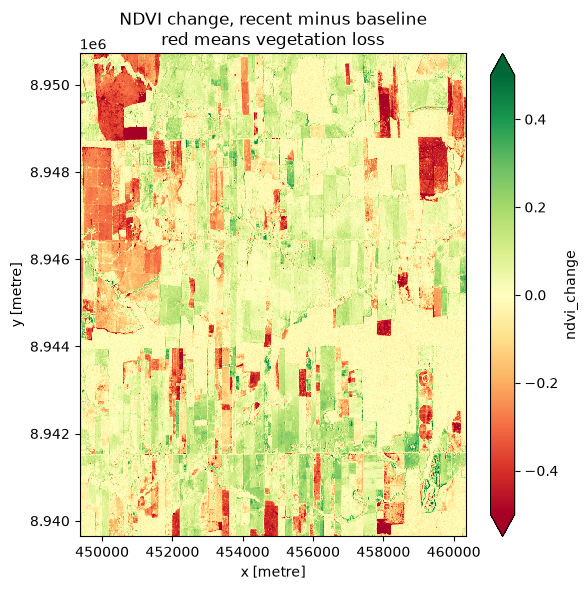

In [16]:
index_names = ["ndvi", "ndmi", "evi", "bsi"]
medians = {}

for index_name in index_names:
    baseline_median = period_median(index_name, "baseline", scenes)
    recent_median = period_median(index_name, "recent", scenes)
    change = (recent_median - baseline_median).rename(f"{index_name}_change")
    change = change.rio.write_crs(baseline_median.rio.crs)
    medians[index_name] = {"baseline": baseline_median, "recent": recent_median, "change": change}

print("medians and change computed for", ", ".join(index_names))

ndvi_change = medians["ndvi"]["change"]
ndvi_change.rio.to_raster(OUTPUT_DIR / "ndvi_change.tif", driver="COG")
print("saved ndvi_change.tif, CRS:", ndvi_change.rio.crs, "shape:", ndvi_change.shape)

fig, ax = plt.subplots(figsize=(6, 6))
ndvi_change.plot(ax=ax, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
ax.set_title("NDVI change, recent minus baseline\nred means vegetation loss")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ndvi_change_map.png", dpi=150)
plt.show()

### Band composites for the foundation model

The spectral indices are not enough for `03_foundation_model.ipynb`: Prithvi-EO-2.0 reads raw reflectance, six bands in a fixed order (blue, green, red, narrow NIR, SWIR 1, SWIR 2). Here the same per-pixel median used for the indices is applied to those six bands, one composite per period.

The narrow NIR band is B8A, not the B08 used for the indices. Prithvi was pretrained on HLS, which uses B8A in that slot because it matches the Landsat NIR band more closely.

The two composites are written to `data/` and not to `outputs/`: they are about 30 MB each and can be rebuilt by rerunning this notebook.

In [17]:
GFM_BANDS = ["B02", "B03", "B04", "B8A", "B11", "B12"]   # order expected by Prithvi
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

crs = next(iter(scenes.values()))["clean"].rio.crs

for period_name in ["baseline", "recent"]:
    period_stacks = [info["clean"][GFM_BANDS].to_array(dim="band")
                     for info in scenes.values() if info["period"] == period_name]
    band_median = xr.concat(period_stacks, dim="time").median(dim="time", skipna=True)
    band_median = band_median.rio.write_crs(crs)
    band_median.attrs["long_name"] = tuple(GFM_BANDS)   # band names stored in the GeoTIFF
    band_median.rio.to_raster(DATA_DIR / f"bands_median_{period_name}.tif")
    print(f"{period_name}: {band_median.shape}, {band_median.dtype}")

baseline: (6, 1108, 1100), float32
recent: (6, 1108, 1100), float32


## 15. Checking for horizontal banding

The change map shows two faint horizontal bands. Before trusting any polygon that falls on those rows, it is worth finding out where they come from. Averaging NDVI along each row gives one value per northing, which turns a pattern that is hard to judge by eye into a curve.

If the bands appeared in one period only, they would bias the change map directly. If both periods show the same pattern at the same rows, it belongs to the landscape itself and mostly cancels out in the subtraction, so the row-wise mean of the change should stay in a narrow range around a constant value, with no spike at any particular row.

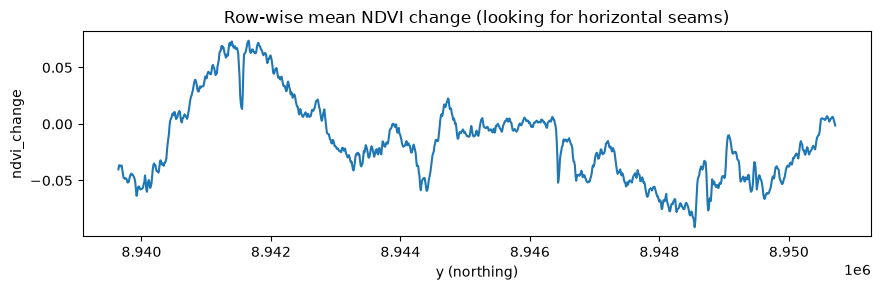

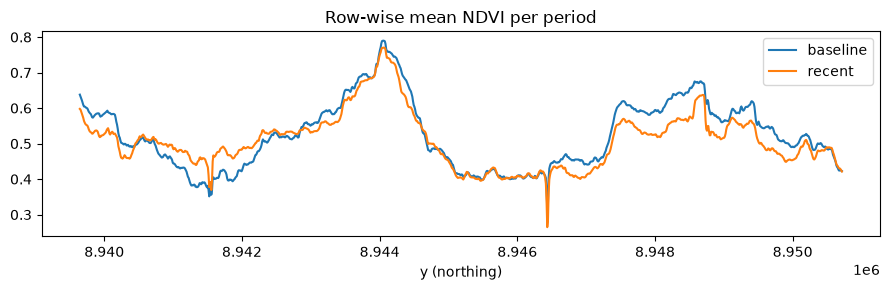

In [18]:
fig, ax = plt.subplots(figsize=(9, 3))
ndvi_change.mean(dim="x", skipna=True).plot(ax=ax)
ax.set_title("Row-wise mean NDVI change (looking for horizontal seams)")
ax.set_xlabel("y (northing)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 3))
medians["ndvi"]["baseline"].mean(dim="x", skipna=True).plot(ax=ax, label="baseline")
medians["ndvi"]["recent"].mean(dim="x", skipna=True).plot(ax=ax, label="recent")
ax.set_title("Row-wise mean NDVI per period")
ax.set_xlabel("y (northing)")
ax.legend()
plt.tight_layout()
plt.show()

## 16. Distribution of the change, before choosing a threshold

A histogram of the NDVI change over the whole AOI, with the candidate threshold marked. Looking at the distribution first avoids picking a cut-off blindly.

Most of the AOI did not change, so the distribution has a sharp peak close to zero. On the negative side there is not just a thin tail but a broad shoulder, peaking around −0.28: a second population of pixels that did change. The threshold at −0.25 cuts through that shoulder, so part of the real loss, between −0.25 and about −0.10, is not flagged. Lowering the threshold would recover some of it but would also eat into the central peak: this trade-off between precision and recall is visible directly in the histogram. The share of pixels below the threshold is printed as a plausibility check.

The distribution also has a tail on the positive side, where vegetation increased. Only the loss side is mapped in this project.

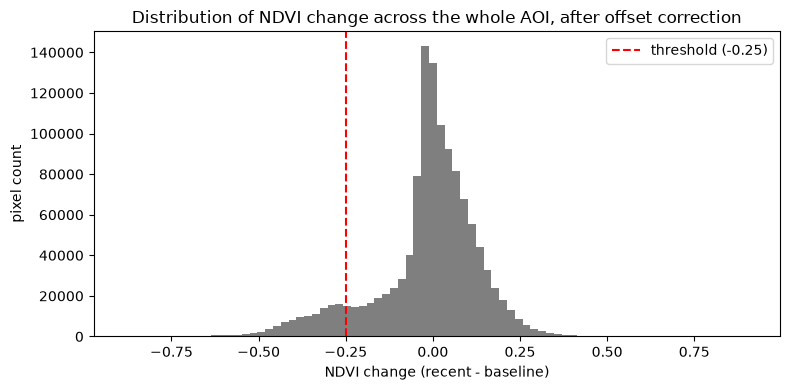

9.3% of all AOI pixels fall below -0.25 NDVI change


In [19]:
change_values = ndvi_change.values
change_values = change_values[np.isfinite(change_values)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(change_values, bins=80, color="tab:gray")
ax.axvline(CHANGE_THRESHOLD, color="red", linestyle="--",
           label=f"threshold ({CHANGE_THRESHOLD})")
ax.set_xlabel("NDVI change (recent - baseline)")
ax.set_ylabel("pixel count")
ax.set_title("Distribution of NDVI change across the whole AOI, after offset correction")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "ndvi_change_histogram.png", dpi=150)
plt.show()

fraction_below = (change_values < CHANGE_THRESHOLD).mean()
print(f"{fraction_below:.1%} of all AOI pixels fall below {CHANGE_THRESHOLD} NDVI change")

## 17. From pixels to polygons

The change map is turned into a list of areas. Pixels where NDVI dropped by more than the threshold are flagged, neighbouring flagged pixels are merged into polygons, and anything smaller than half a hectare is dropped, so isolated noisy pixels do not end up looking like real change.

Areas are measured in a metric projection (UTM), since square degrees mean nothing on the ground. The result is saved as GeoJSON in EPSG:4326, the format that QGIS, geojson.io and web maps expect by default.

In [20]:
loss_gdf = vectorize_loss(ndvi_change, CHANGE_THRESHOLD, MIN_AREA_M2)

loss_gdf.to_crs(4326).to_file(OUTPUT_DIR / "vegetation_loss.geojson", driver="GeoJSON")
print(f"{len(loss_gdf)} polygons kept after the minimum area filter")
print(f"total flagged area: {loss_gdf['area_m2'].sum() / 10_000:.1f} hectares")
loss_gdf.head()

130 polygons kept after the minimum area filter
total flagged area: 1051.3 hectares


,geometry,area_m2
0,"POLYGON ((451230 8950660, 451230 8950640, 4512...",5100.0
1,"POLYGON ((449760 8950720, 449760 8950710, 4497...",46400.0
2,"POLYGON ((450450 8950720, 450450 8950710, 4504...",227500.0
3,"POLYGON ((456940 8950490, 456940 8950480, 4569...",48800.0
4,"POLYGON ((451510 8950720, 451510 8950660, 4515...",83200.0


## 18. From candidates to alerts

An NDVI drop alone can come from a seasonal effect that slipped through the window choice, or from a processing artefact, as the offset bug showed. Two more checks turn a candidate polygon into an alert.

- **Bare soil confirmation.** The mean BSI change inside the polygon must rise by more than the confirmation threshold. Exposed soil is what clearing leaves behind, so it is independent support for the NDVI drop.
- **Water exclusion.** Land that stays below an NDVI of -0.1 in both periods is most likely water. Any polygon touching it is dropped.

Water is now excluded before ranking, so the list is ranked once on the polygons that survive. Before the refactoring, the ranked list was saved first and corrected afterwards.

In [21]:
water_gdf = water_like_polygons(medians["ndvi"]["baseline"], medians["ndvi"]["recent"],
                                threshold=WATER_NDVI_THRESHOLD)
print(len(water_gdf), "persistently low-NDVI regions (likely water)")

alerts = build_alerts(
    loss_gdf,
    ndvi_change=ndvi_change,
    bsi_change=medians["bsi"]["change"],
    water=water_gdf,
    bsi_threshold=BSI_CONFIRMATION_THRESHOLD,
)
print(f"{len(loss_gdf)} candidate polygons -> {len(alerts)} alerts")

37 persistently low-NDVI regions (likely water)
130 candidate polygons -> 129 alerts


### How much each check removed

Counting what each filter takes out shows whether it does any work. In the first version of this project every NDVI polygon also passed the BSI check, which left open whether the BSI margin was too loose to reject anything.

In [22]:
bsi_means = loss_gdf.geometry.apply(
    lambda geom: float(medians["bsi"]["change"].rio.clip([geom], loss_gdf.crs).mean(skipna=True))
)
passes_bsi = bsi_means > BSI_CONFIRMATION_THRESHOLD
touches_water = loss_gdf.geometry.intersects(water_gdf.union_all()) if len(water_gdf) else False

print(f"pass the BSI check:   {passes_bsi.sum()} of {len(loss_gdf)} ({passes_bsi.mean():.0%})")
print(f"touch a water region: {int(np.sum(touches_water))}")

pass the BSI check:   130 of 130 (100%)
touch a water region: 1


## 19. The ranked list

Alerts are ranked by area, largest first: a larger contiguous loss is both more likely to be real and more urgent for a field team. Each one also gets a rough severity label, combining area and the strength of the NDVI drop. The cut-offs for the label (5 hectares and an NDVI drop of 0.35 for "high") are round numbers chosen by judgement, not calibrated values.

The file is saved in EPSG:4326, with the centroid of each alert so a team can navigate to it.

In [23]:
alerts_4326 = alerts.to_crs(4326)
alerts_4326.to_file(OUTPUT_DIR / "deforestation_alerts.geojson", driver="GeoJSON")

print(alerts["severity"].value_counts().to_string())
alerts[["priority_rank", "severity", "area_ha", "mean_ndvi_change", "mean_bsi_change",
        "centroid_lat", "centroid_lon"]].head(10).round(4)

severity
medium    70
low       40
high      19


,priority_rank,severity,area_ha,mean_ndvi_change,mean_bsi_change,centroid_lat,centroid_lon
0,1,high,176.99,-0.3873,0.2130,-9.5025,-63.4512
1,2,medium,163.47,-0.3059,0.1795,-9.5226,-63.4545
2,3,high,103.38,-0.4090,0.4132,-9.5154,-63.3699
3,4,high,53.67,-0.4161,0.3878,-9.5031,-63.3817
4,5,medium,46.83,-0.3390,0.3238,-9.5038,-63.3637
5,6,high,31.04,-0.4035,0.4109,-9.5887,-63.4119
6,7,high,28.49,-0.3631,0.2576,-9.5585,-63.4362
7,8,medium,22.75,-0.3139,0.2053,-9.4942,-63.4464
8,9,medium,21.75,-0.2876,0.1235,-9.5348,-63.4423
9,10,high,20.47,-0.3533,0.3938,-9.5127,-63.4407


## 20. Plain-language summary

The ranked table assumes the reader knows what NDVI or BSI mean. This paragraph is for someone who has never opened a satellite image, for instance a field coordinator deciding where to send a team this week.

In [24]:
summary_text = summarise_alerts(alerts, start_year=2018, end_year=2023)
print(summary_text)

Between 2018 and 2023, 129 areas show a strong drop in vegetation (NDVI), supported by a rise in bare soil, for about 1050.3 hectares in total. 19 of them are high severity, meaning both large and strongly affected. The largest covers about 177.0 hectares, centred near latitude -9.5025, longitude -63.4512.


## 21. Interactive map

Twelve raster layers, baseline, recent and change for each of the four indices, with the alerts on top. Only one index layer is visible at a time, while the alerts can be switched on and off independently. The map is also saved as an HTML file that opens in any browser.


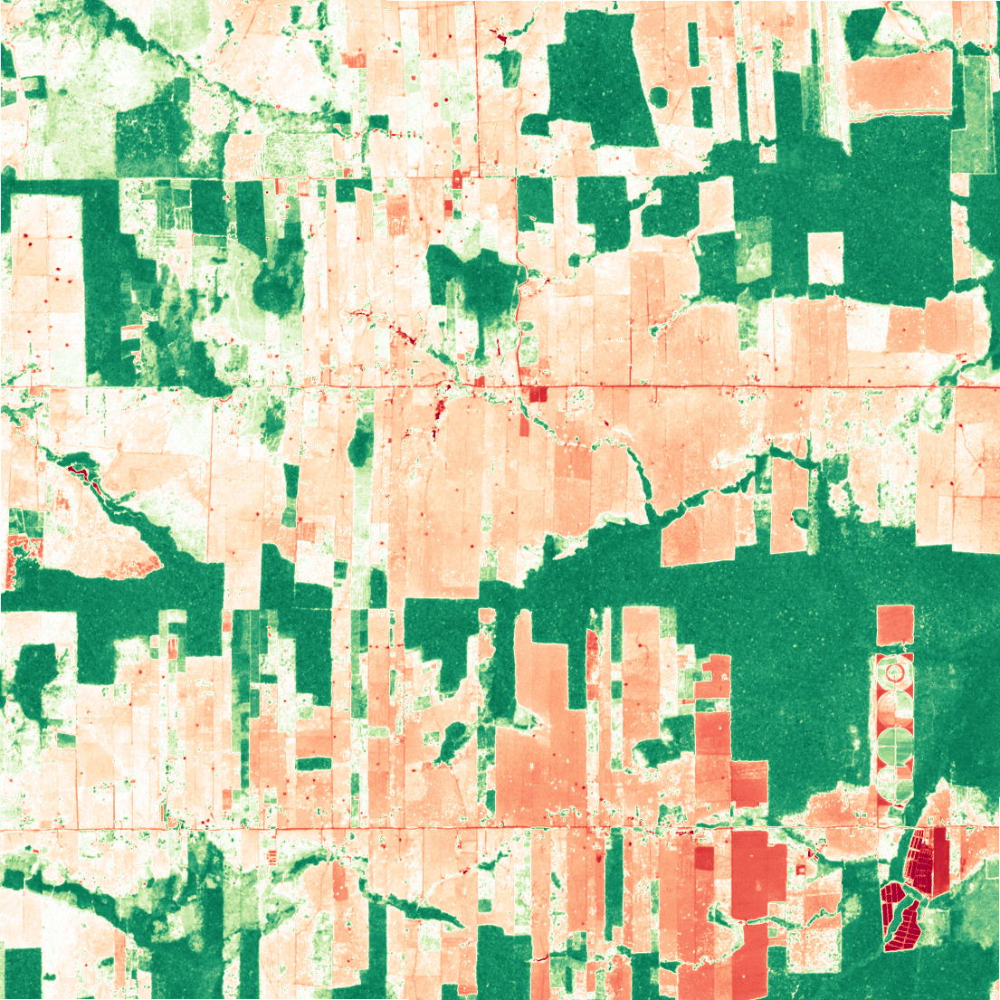
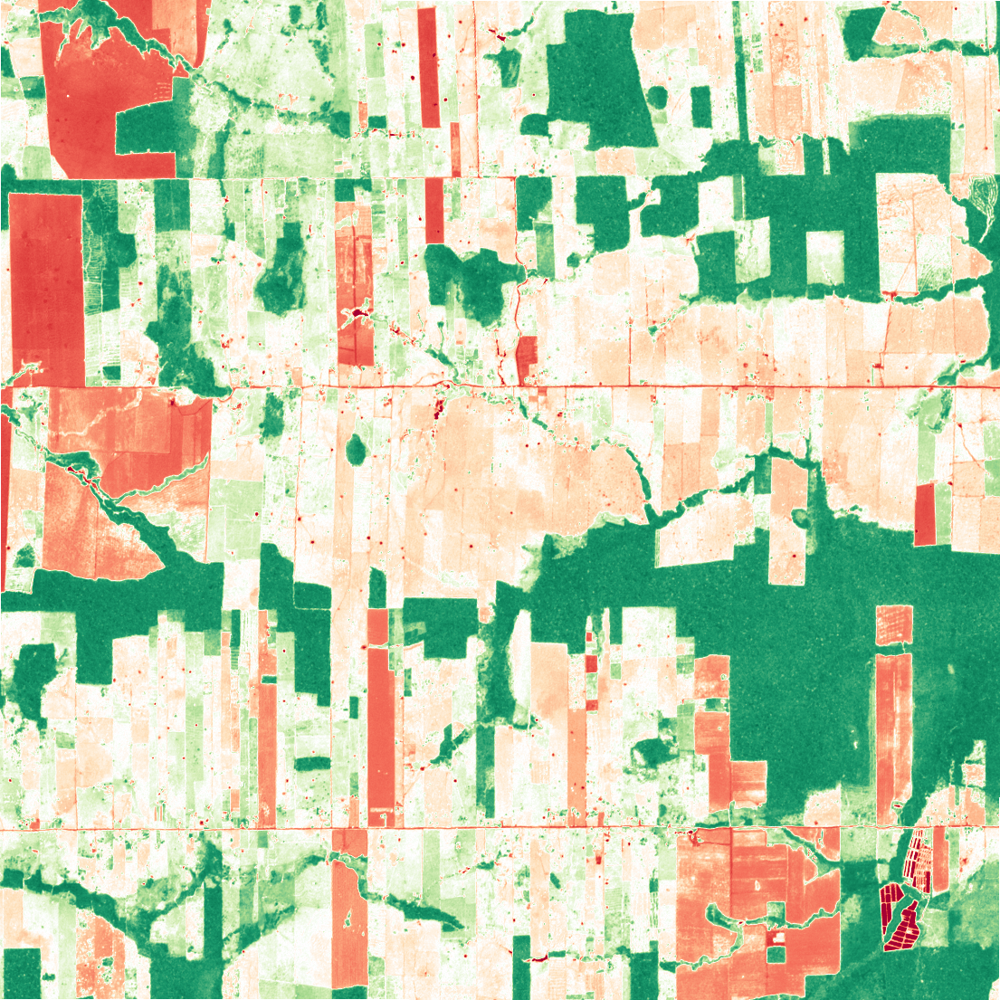
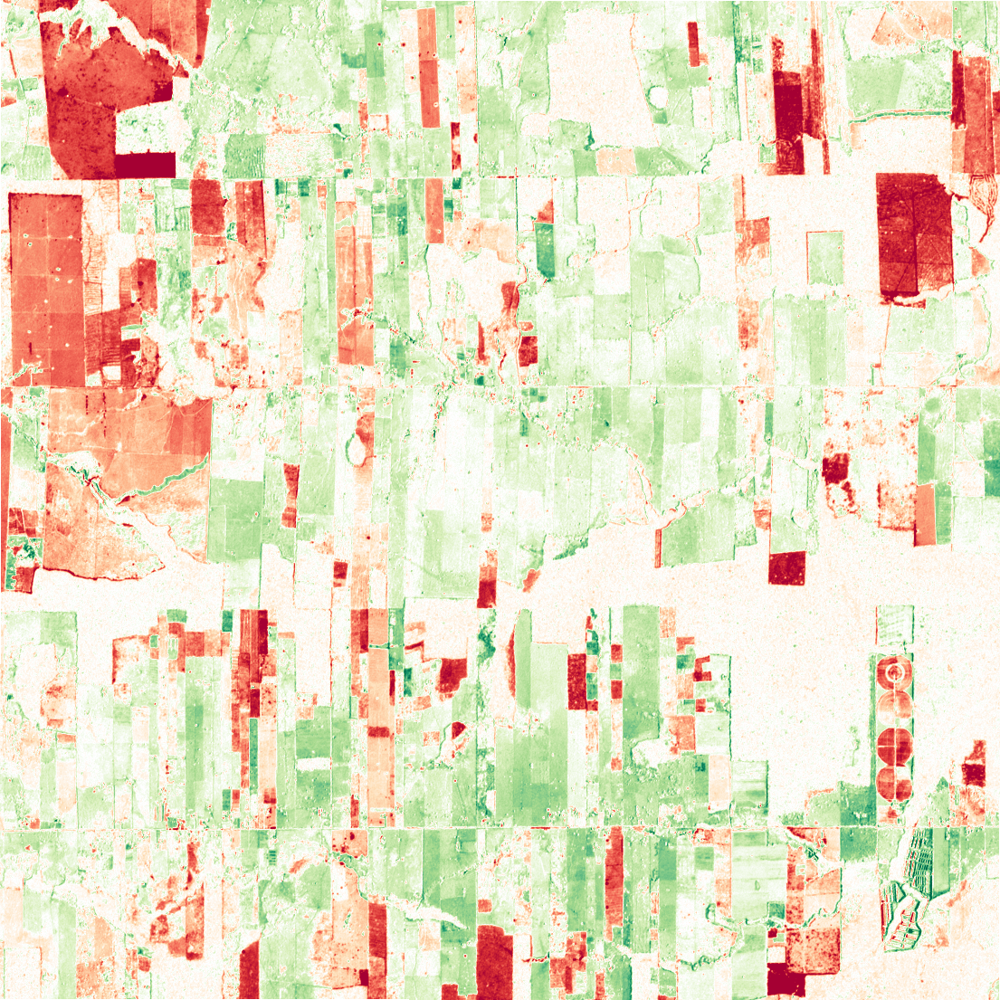
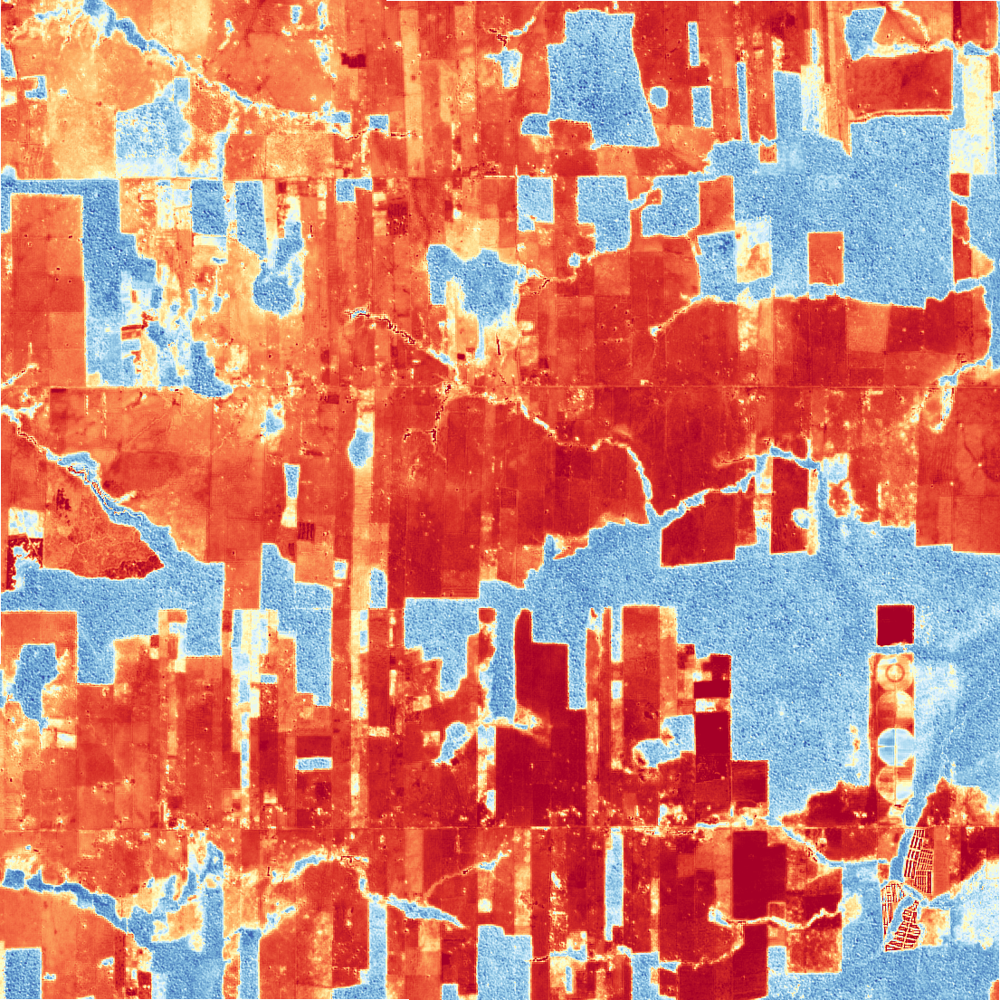
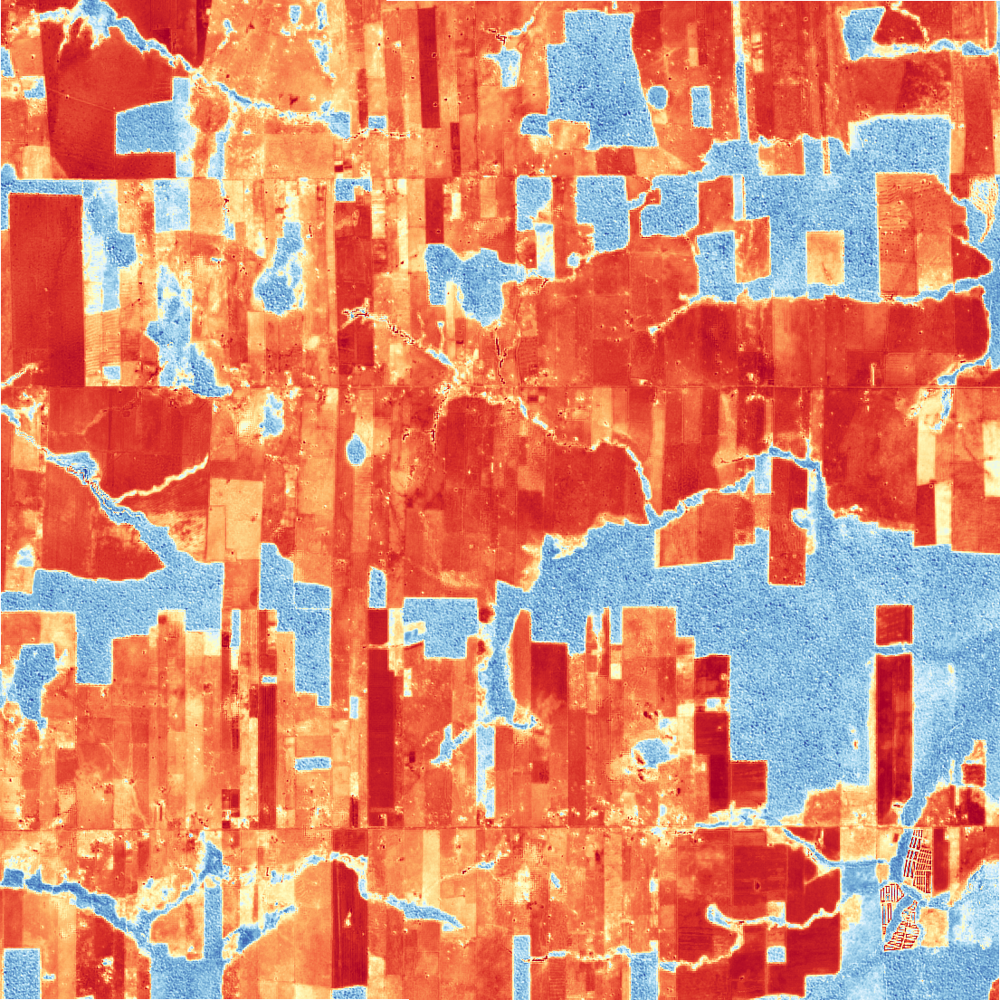
...
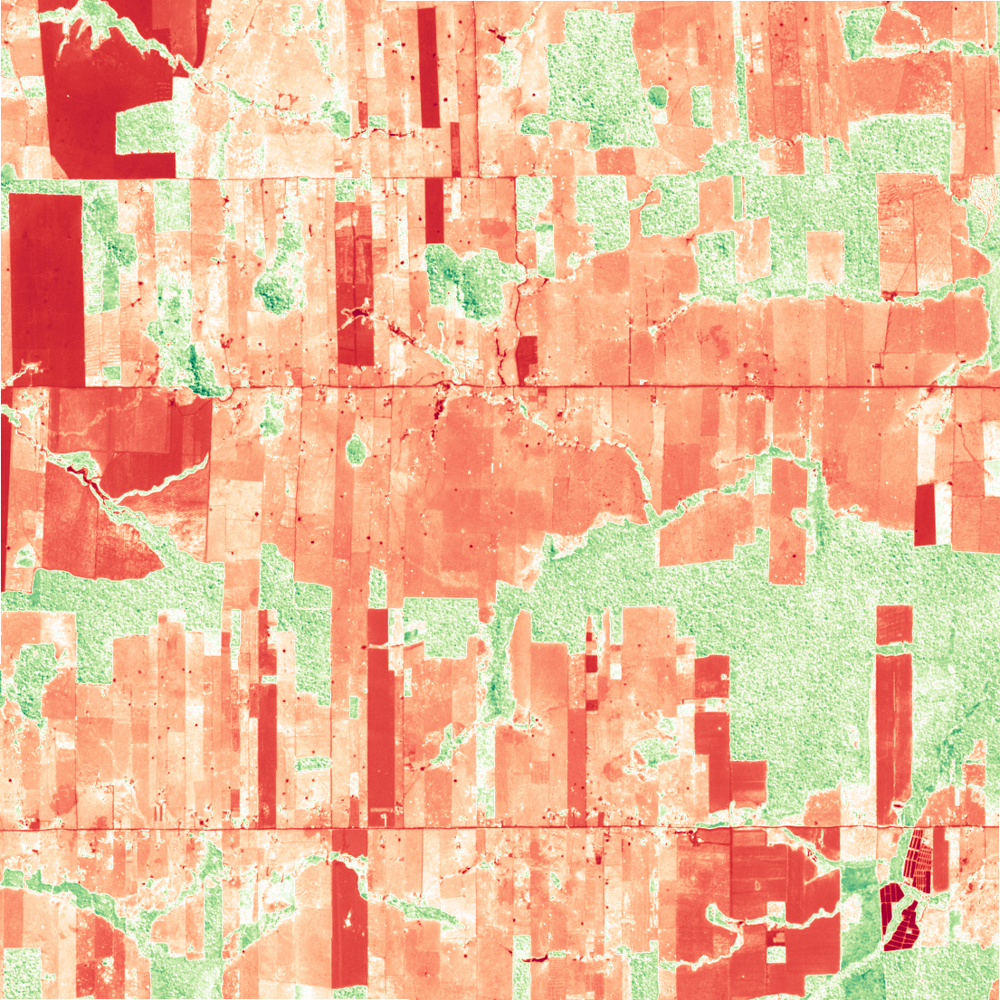
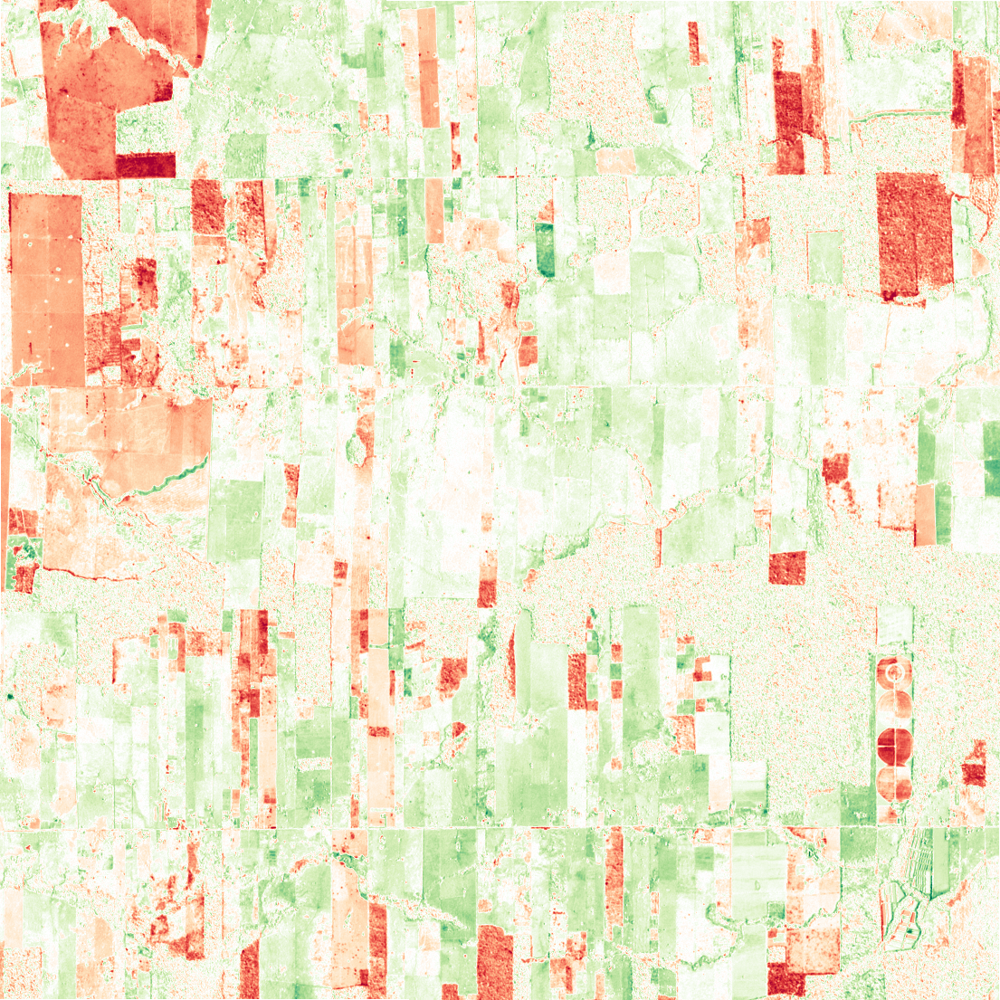
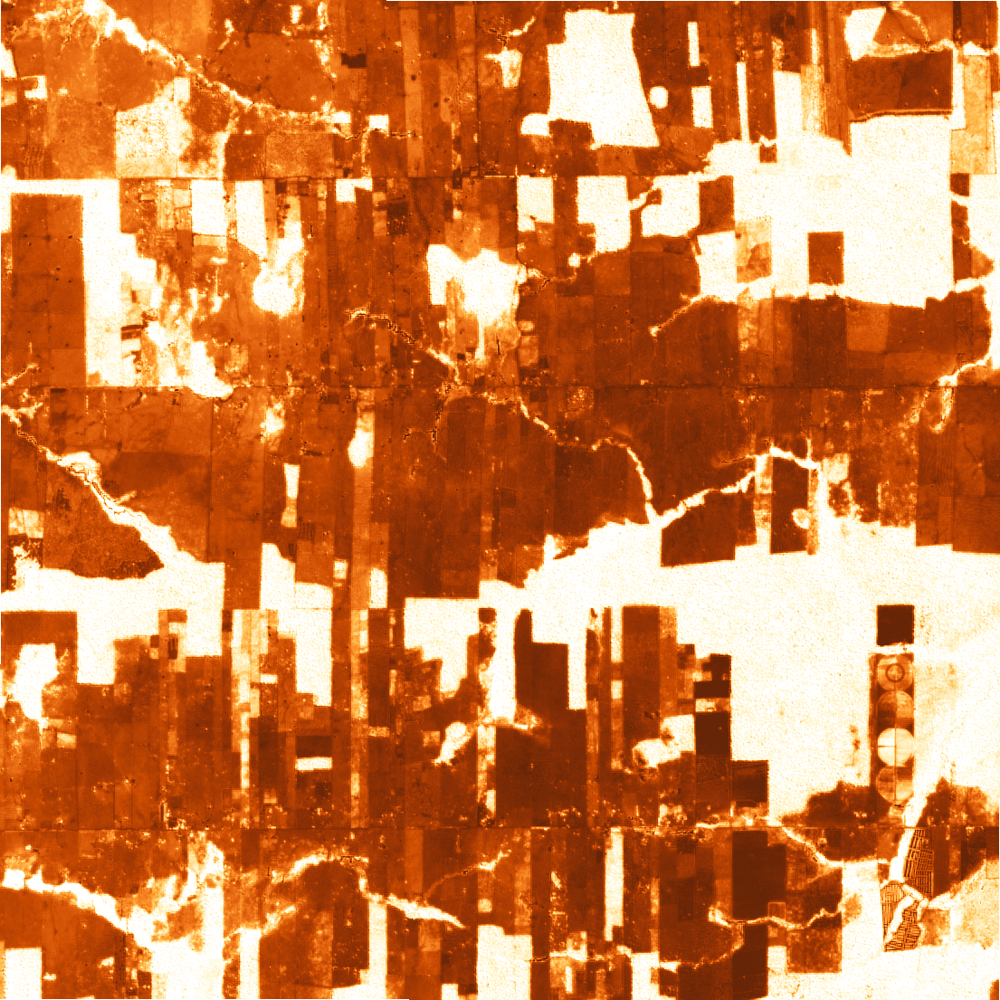
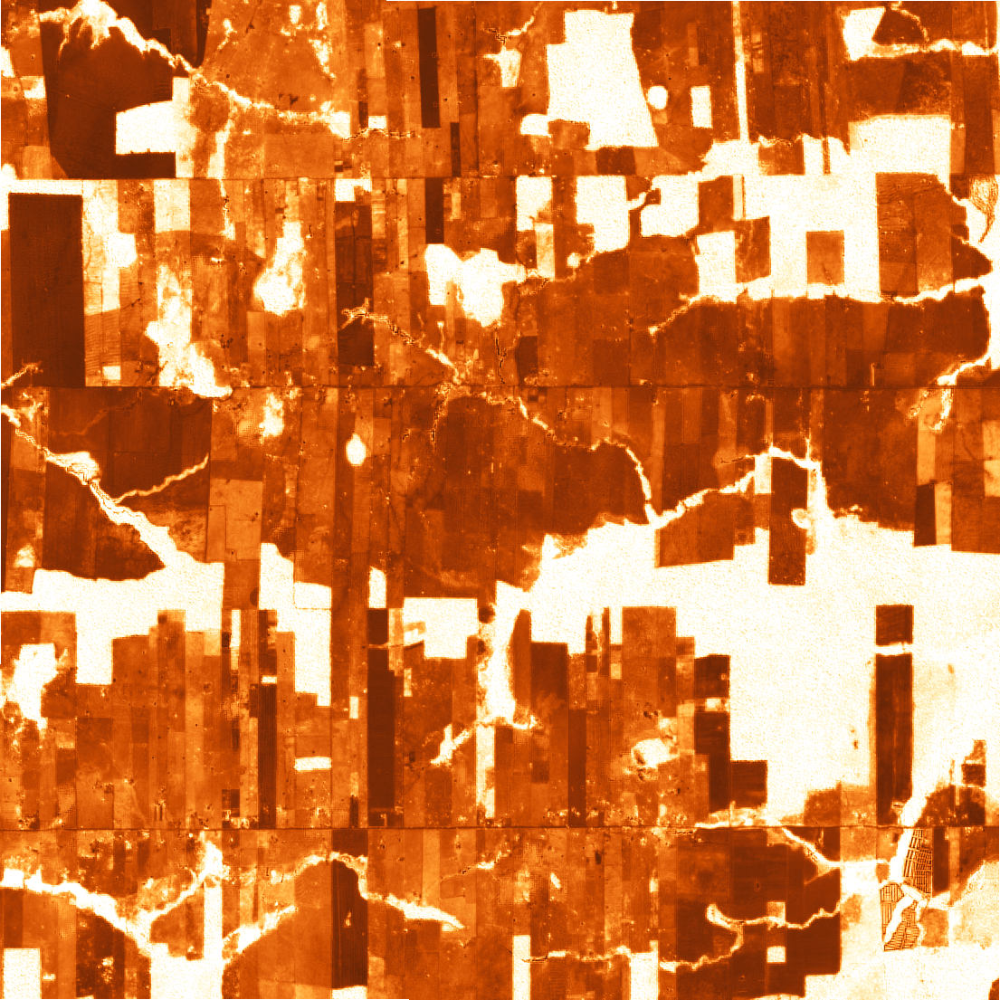
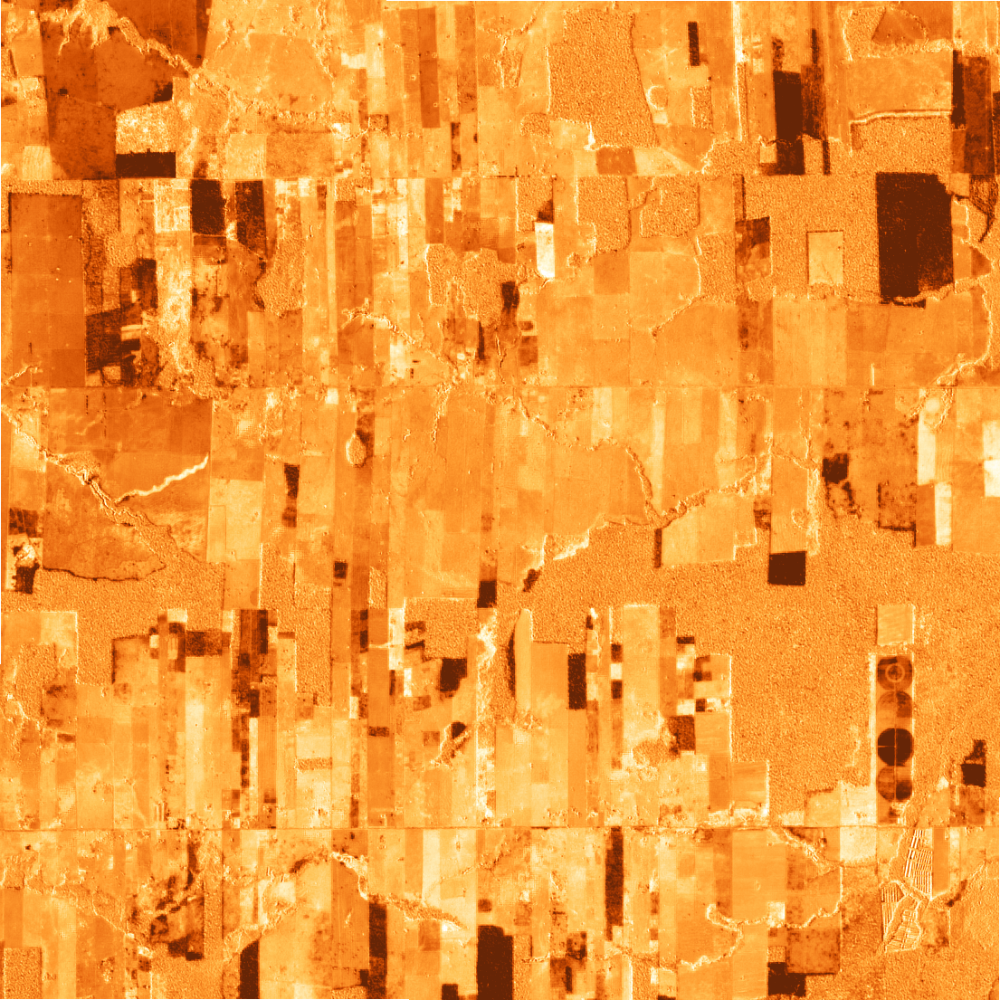

In [25]:
color_scales = {
    "ndvi": ("RdYlGn", 0, 0.9, -0.5, 0.5),
    "ndmi": ("RdYlBu", -0.3, 0.5, -0.5, 0.5),
    "evi": ("RdYlGn", 0, 0.9, -0.5, 0.5),
    "bsi": ("YlOrBr", -0.3, 0.3, -0.4, 0.4),
}

aoi_centre = [(bbox[1] + bbox[3]) / 2, (bbox[0] + bbox[2]) / 2]
m = folium.Map(location=aoi_centre, zoom_start=13, tiles="OpenStreetMap")

index_layers = []
for index_name in index_names:
    cmap_name, val_min, val_max, change_min, change_max = color_scales[index_name]
    label = index_name.upper()
    index_layers.append(raster_to_overlay(medians[index_name]["baseline"], cmap_name, val_min, val_max, f"{label}, baseline"))
    index_layers.append(raster_to_overlay(medians[index_name]["recent"], cmap_name, val_min, val_max, f"{label}, recent"))
    index_layers.append(raster_to_overlay(medians[index_name]["change"], cmap_name, change_min, change_max, f"{label}, change"))

for layer in index_layers:
    layer.add_to(m)

folium.GeoJson(
    alerts_4326[["priority_rank", "severity", "area_ha", "geometry"]],
    name="Deforestation alerts",
    style_function=lambda feature: {"color": "black", "fillColor": "red", "fillOpacity": 0.3, "weight": 1},
    tooltip=folium.GeoJsonTooltip(fields=["priority_rank", "severity", "area_ha"]),
).add_to(m)

GroupedLayerControl(groups={"Index (choose one)": index_layers},
                    exclusive_groups=True, collapsed=False).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)

m.save(OUTPUT_DIR / "interactive_map.html")
m

## 22. Saving the run

Everything needed to describe this run, in one small file: the AOI, the time windows, the scenes used, the thresholds and the headline numbers. The validation notebook reads the AOI from here instead of a copied bounding box, and the assistant can answer questions like "which scenes were used?" without rerunning anything.

In [26]:
run_info = {
    "generated_on": date.today().isoformat(),
    "aoi_bbox": [round(float(v), 6) for v in bbox],
    "baseline_window": BASELINE_WINDOW,
    "recent_window": RECENT_WINDOW,
    "scenes": {
        "baseline": [item.id for item in baseline_scenes],
        "recent": [item.id for item in recent_scenes],
    },
    "thresholds": {
        "ndvi_change": CHANGE_THRESHOLD,
        "min_area_m2": MIN_AREA_M2,
        "bsi_confirmation": BSI_CONFIRMATION_THRESHOLD,
        "water_ndvi": WATER_NDVI_THRESHOLD,
    },
    "results": {
        "candidate_polygons": int(len(loss_gdf)),
        "alerts": int(len(alerts)),
        "alert_area_ha": round(float(alerts["area_ha"].sum()), 1),
        "alerts_by_severity": {k: int(v) for k, v in alerts["severity"].value_counts().items()},
    },
    "summary": summary_text,
}

with open(OUTPUT_DIR / "run_info.json", "w") as f:
    json.dump(run_info, f, indent=2)

print(json.dumps(run_info, indent=2))

{
  "generated_on": "2026-10-20",
  "aoi_bbox": [
    -63.461313,
    -9.592137,
    -63.361313,
    -9.492137
  ],
  "baseline_window": "2018-06-01/2018-09-30",
  "recent_window": "2023-06-01/2023-09-30",
  "scenes": {
    "baseline": [
      "S2A_MSIL2A_20180819T142751_R053_T20LMQ_20201011T035719",
      "S2A_MSIL2A_20180829T142751_R053_T20LMQ_20201103T112224",
      "S2A_MSIL2A_20180720T142751_R053_T20LMQ_20201011T175511",
      "S2A_MSIL2A_20180908T142751_R053_T20LMQ_20201011T100319",
      "S2A_MSIL2A_20180710T142751_R053_T20LMQ_20201011T140724"
    ],
    "recent": [
      "S2B_MSIL2A_20230629T142719_R053_T20LMQ_20241002T184523",
      "S2A_MSIL2A_20230724T142721_R053_T20LMQ_20230724T233545",
      "S2A_MSIL2A_20230922T142711_R053_T20LMQ_20241026T093629",
      "S2B_MSIL2A_20230828T142719_R053_T20LMQ_20241019T002816",
      "S2B_MSIL2A_20230808T142719_R053_T20LMQ_20241030T021940"
    ]
  },
  "thresholds": {
    "ndvi_change": -0.25,
    "min_area_m2": 5000,
    "bsi_confirmation